# Coffee roasting: a neural network forward pass by hand

This notebook builds a small neural network with NumPy. The network predicts if a coffee roast is good. It uses two inputs:

* the roasting temperature, in degrees Celsius (°C)
* the roasting duration, in minutes

You write the math of the forward pass. The forward pass is the computation that turns the inputs into a prediction. The notebook gives you the data, the trained weights, and a check for each step.

This notebook does not train the network. Training is the step that finds the weights. You get weights that training already found.

You need NumPy. matplotlib is optional: it draws the pictures. PyTorch is optional: the last bonus uses it.

## How to use this notebook

1. Run the cells from top to bottom.
2. If a cell starts with `# TODO` or `# BONUS TODO`, replace the `raise NotImplementedError(...)` line with your code. Then run the cell.
3. Run the check cell below it:
   * `PASS`: go to the next step.
   * `FAIL`: read the message, fix your code, and run both cells again.
   * `NOT DONE`: a function still has its `raise NotImplementedError(...)` line.
4. If you change a function, run its cell again before you run a check.

## The network

```text
x = [temperature, duration]      2 inputs, normalized
             |
             v
layer 1: 3 neurons, sigmoid      a1, shape (3,)
             |
             v
layer 2: 1 neuron, sigmoid       a2, shape (1,)
             |
             v
a2 = the probability that the coffee is good. Good if a2 >= 0.5.
```

Each neuron $j$ in a layer does two steps:

1. It combines all inputs of the layer into one number: $z_j = \vec{w}_j \cdot \vec{a}_{in} + b_j$
2. It applies the activation function $g$: $a_j = g(z_j)$

$\vec{w}_j$ holds the weights of neuron $j$, and $b_j$ is its bias. This network uses the sigmoid activation function: $g(z) = \dfrac{1}{1 + e^{-z}}$

In [1]:
import numpy as np

import coffee_plots
from coffee_checks import (check_dense, check_forward, check_forward_vectorized,
                           check_normalize, check_predict, check_sigmoid)

np.set_printoptions(precision=3, suppress=True)  # print arrays with 3 decimals

## 1. The data

Each example is one coffee roast: `[temperature, duration]`. The label is 1 for a good coffee and 0 for a bad coffee.

`is_good_coffee()` is the true rule that makes the labels. The network does not know this rule. Training made the weights from the examples only. Later, you compare the network with the rule.

In [2]:
def is_good_coffee(temperature, duration):
    """The true rule. Returns True if the coffee is good."""
    return (175 < temperature < 260                      # not too cold and not too hot
            and 12 < duration < 15                       # not too short and not too long
            and duration <= 21 - 3 * temperature / 85)   # a hotter roast must be shorter


def load_coffee_data():
    """Makes 200 random coffee roasts and their labels (1 = good, 0 = bad)."""
    rng = np.random.default_rng(2)          # a fixed seed gives the same data every time
    X = rng.random(400).reshape(-1, 2)      # 200 rows, 2 columns, values from 0 to 1
    X[:, 0] = X[:, 0] * (285 - 150) + 150   # column 0: temperature, 150 to 285 °C
    X[:, 1] = X[:, 1] * 4 + 11.5            # column 1: duration, 11.5 to 15.5 min
    Y = np.array([[int(is_good_coffee(t, d))] for t, d in X])
    return X, Y


X, Y = load_coffee_data()
print("X shape:", X.shape, "-> one row per coffee: [temperature, duration]")
print("Y shape:", Y.shape, "-> one label per coffee: 1 = good, 0 = bad")
print("Good coffees:", Y.sum(), "of", len(Y))
print("The first 5 coffees:")
for x_i, y_i in zip(X[:5], Y[:5]):
    print(f"  {x_i[0]:6.1f} °C  {x_i[1]:5.2f} min  ->  label {y_i[0]}")

X shape: (200, 2) -> one row per coffee: [temperature, duration]
Y shape: (200, 1) -> one label per coffee: 1 = good, 0 = bad
Good coffees: 43 of 200
The first 5 coffees:
   185.3 °C  12.69 min  ->  label 1
   259.9 °C  11.87 min  ->  label 0
   231.0 °C  14.41 min  ->  label 0
   175.4 °C  11.72 min  ->  label 0
   187.1 °C  14.13 min  ->  label 1


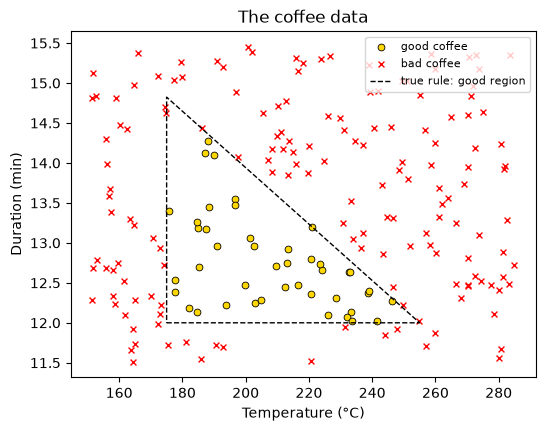

In [3]:
coffee_plots.plot_data(X, Y)

## 2. Normalize the inputs (TODO 1)

The temperature is about 200, and the duration is about 13. The two features have very different sizes. Training works better when all features have a similar size. Thus training used normalized features. A normalized feature has a mean of 0 and a standard deviation of 1:

$$x_{norm} = \frac{x - \mu}{\sigma}$$

* $\mu$ (`mean`) is the mean of the feature in the training data.
* $\sigma$ (`std`) is the standard deviation of the feature in the training data.

The network gives correct answers only for normalized inputs. Normalize every new coffee with the same `mean` and `std`.

In [ ]:
mean = X.mean(axis=0)   # shape (2,): the mean temperature and the mean duration
std = X.std(axis=0)     # shape (2,): the standard deviation of each feature
print("mean:", mean)
print("std: ", std)

In [ ]:
# TODO 1: normalize the features.
def normalize(X, mean, std):
    """Normalizes each column of X with the mean and std of the training data.

    Args:
        X: raw features, shape (m, 2). m is the number of coffees.
        mean: the mean of each column, shape (2,).
        std: the standard deviation of each column, shape (2,).

    Returns:
        X_norm: the normalized features, shape (m, 2). Do not change X itself.
    """
    # Write your code here. Hint: NumPy can subtract a shape (2,) array from
    # each row of a shape (m, 2) array. This is called broadcasting.
    raise NotImplementedError("TODO 1 is not done: write the math in normalize()")

In [ ]:
check_normalize(normalize)

## 3. The trained weights

Training found these weights. Look at the shapes:

* `W1` has shape (2, 3): 2 inputs and 3 neurons. Column `j`, `W1[:, j]`, holds the 2 weights of neuron `j`.
* `b1` has shape (3,): one bias for each neuron.
* `W2` has shape (3, 1): 3 inputs (the 3 outputs of layer 1) and 1 neuron.
* `b2` has shape (1,).

In [ ]:
# Layer 1: 2 inputs -> 3 neurons.
W1 = np.array([
    [-8.93,  0.29, 12.90],   # row 0: the weights for input 0 (temperature)
    [-0.10, -7.32, 10.81],   # row 1: the weights for input 1 (duration)
])
b1 = np.array([-9.82, -9.28, 0.96])

# Layer 2: 3 inputs -> 1 neuron.
W2 = np.array([
    [-31.18],
    [-27.59],
    [-32.56],
])
b2 = np.array([15.41])

print("W1:", W1.shape, "  b1:", b1.shape)
print("W2:", W2.shape, "  b2:", b2.shape)
print("The weights of neuron 0 in layer 1, W1[:, 0]:", W1[:, 0])

## 4. The activation function: sigmoid (TODO 2)

$$g(z) = \frac{1}{1 + e^{-z}}$$

The sigmoid changes any number into a number between 0 and 1:

* A large positive $z$ gives a value near 1.
* A large negative $z$ gives a value near 0.
* $g(0) = 0.5$.

Your function must work for one number and for a NumPy array. For an array, it applies $g$ to each element.

In [ ]:
# TODO 2: the sigmoid function.
def sigmoid(z):
    """Computes g(z) = 1 / (1 + e^(-z)).

    Args:
        z: a number or a NumPy array of any shape.

    Returns:
        g(z), with the same shape as z.
    """
    # Write your code here. Hint: np.exp(z) computes e^z. It works on one
    # number and on a whole array.
    raise NotImplementedError("TODO 2 is not done: write the math in sigmoid()")

In [ ]:
check_sigmoid(sigmoid)

## 5. One dense layer (TODO 3)

A dense layer is a group of neurons. Each neuron gets all inputs of the layer. For each neuron $j$:

$$z_j = \vec{w}_j \cdot \vec{a}_{in} + b_j \qquad a_{out}[j] = g(z_j)$$

* $\vec{w}_j$ is column $j$ of `W`, which is `W[:, j]`.
* $\vec{w}_j \cdot \vec{a}_{in}$ is the dot product. Multiply the two vectors element by element, then add the results. `np.dot` does this.
* `g` is the activation function. The caller gives it, for example `sigmoid`.

The loop over the neurons is ready. You write the math for one neuron.

In [ ]:
# TODO 3: one dense layer, for one coffee.
def dense(a_in, W, b, g):
    """Computes the outputs of all neurons in one layer.

    Args:
        a_in: the inputs of the layer, shape (n_in,).
        W: the weights, shape (n_in, n_out). Column j holds the weights of neuron j.
        b: the biases, shape (n_out,).
        g: the activation function, for example sigmoid.

    Returns:
        a_out: the outputs of the neurons, shape (n_out,).
    """
    n_out = W.shape[1]          # the number of neurons in this layer
    a_out = np.zeros(n_out)
    for j in range(n_out):
        w_j = W[:, j]           # the weights of neuron j, shape (n_in,)
        b_j = b[j]              # the bias of neuron j, one number
        # Write your code here: compute z_j, then a_out[j].
        raise NotImplementedError("TODO 3 is not done: write the math in dense()")
    return a_out

In [ ]:
check_dense(dense)

## 6. The forward pass (TODO 4)

The forward pass runs the layers in order. The output of one layer is the input of the next layer:

* Layer 1 takes the coffee `x` (2 values) and gives `a1` (3 values).
* Layer 2 takes `a1` (3 values) and gives `a2` (1 value).

Both layers use the sigmoid activation function. Use your `dense()` function.

In [ ]:
# TODO 4: the forward pass, for one coffee.
def forward(x, W1, b1, W2, b2):
    """Runs the network on one coffee.

    Args:
        x: one normalized coffee [temperature, duration], shape (2,).
        W1, b1: the weights and biases of layer 1, shapes (2, 3) and (3,).
        W2, b2: the weights and biases of layer 2, shapes (3, 1) and (1,).

    Returns:
        a2: the output of layer 2, shape (1,). It is the probability that the
            coffee is good.
    """
    # Write your code here: compute a1 with layer 1, then a2 with layer 2.
    raise NotImplementedError("TODO 4 is not done: write the math in forward()")

In [ ]:
check_forward(forward)

## 7. Predict good or bad (TODO 5)

`predict_proba()` is ready. It runs `forward()` on each coffee and collects the probabilities.

`predict()` changes each probability into a decision:

$$\hat{y} = \begin{cases} 1 \ \text{(good)} & \text{if } a2 \ge \text{threshold} \\ 0 \ \text{(bad)} & \text{if } a2 < \text{threshold} \end{cases}$$

The usual threshold is 0.5.

In [ ]:
def predict_proba(X, W1, b1, W2, b2):
    """Runs forward() on each coffee. This function is ready.

    Args:
        X: normalized coffees, shape (m, 2).
        W1, b1, W2, b2: the weights and biases.

    Returns:
        p: the probability that each coffee is good, shape (m, 1).
    """
    m = X.shape[0]
    p = np.zeros((m, 1))
    for i in range(m):
        p[i] = forward(X[i], W1, b1, W2, b2)   # X[i] is coffee i, shape (2,)
    return p

In [ ]:
# TODO 5: change the probabilities into decisions.
def predict(X, W1, b1, W2, b2, threshold=0.5):
    """Predicts 1 (good) or 0 (bad) for each coffee.

    Args:
        X: normalized coffees, shape (m, 2).
        W1, b1, W2, b2: the weights and biases.
        threshold: a coffee is good if its probability is >= threshold.

    Returns:
        yhat: 1 or 0 for each coffee, shape (m, 1).
    """
    # Write your code here. Call predict_proba() first.
    # Hint: p >= threshold compares each element of the array p and gives
    # True or False. .astype(int) changes True to 1 and False to 0.
    raise NotImplementedError("TODO 5 is not done: write the math in predict()")

In [ ]:
check_predict(predict)

## 8. Run your network

If all checks print `PASS`, your network works. First, follow one coffee through the network.

In [ ]:
coffee = np.array([[200.0, 13.9]])      # one coffee: 200 °C and 13.9 min, shape (1, 2)

x = normalize(coffee, mean, std)[0]     # shape (2,)
a1 = dense(x, W1, b1, sigmoid)          # the output of layer 1, shape (3,)
a2 = forward(x, W1, b1, W2, b2)         # the output of layer 2, shape (1,)

print("raw input          :", coffee[0])
print("normalized input x :", x)
print("layer 1 output a1  :", a1)
print("layer 2 output a2  :", a2)
print("prediction         :", "good" if a2[0] >= 0.5 else "bad")

Now run the network on more coffees. The last column shows the true rule.

In [ ]:
coffees = np.array([
    [200.0, 13.9],
    [200.0, 17.0],
    [165.0, 13.0],
    [220.0, 11.8],
    [250.0, 14.0],
    [230.0, 12.5],
    [180.0, 14.5],
])
coffees_norm = normalize(coffees, mean, std)
p = predict_proba(coffees_norm, W1, b1, W2, b2)
yhat = predict(coffees_norm, W1, b1, W2, b2)

print("temperature  duration  P(good)  network  true rule")
for (t, d), p_i, yhat_i in zip(coffees, p[:, 0], yhat[:, 0]):
    network = "good" if yhat_i == 1 else "bad"
    truth = "good" if is_good_coffee(t, d) else "bad"
    print(f"{t:8.1f} °C  {d:4.1f} min  {p_i:7.3f}  {network:7}  {truth}")

Check all 200 coffees of the training data. The expected result is 200 of 200 correct.

In [ ]:
yhat = predict(normalize(X, mean, std), W1, b1, W2, b2)
n_correct = int(np.sum(yhat == Y))
print(f"Correct: {n_correct} of {len(Y)} coffees ({n_correct / len(Y):.0%})")

### Try your own coffee

Change the two numbers, then run the cell.

In [ ]:
temperature = 210.0   # °C
duration = 13.0       # minutes

x = normalize(np.array([[temperature, duration]]), mean, std)[0]
a2 = forward(x, W1, b1, W2, b2)
print(f"{temperature} °C, {duration} min -> P(good) = {a2[0]:.3f}")
print("network  :", "good" if a2[0] >= 0.5 else "bad")
print("true rule:", "good" if is_good_coffee(temperature, duration) else "bad")

## 9. See what each neuron learned

The next cell runs your network on a grid of 10,000 coffees. The grid covers all temperatures and durations of the data. Each picture shows the output of one neuron for each coffee. A dark color is an output near 1.

* Gold circles are good coffees. Red crosses are bad coffees.
* In the last picture, the solid line is where a2 = 0.5. The dashed line is the true rule.

In [ ]:
X_grid = coffee_plots.make_grid()                  # 10,000 raw coffees, shape (10000, 2)
X_grid_norm = normalize(X_grid, mean, std)
A1_grid = np.array([dense(x, W1, b1, sigmoid) for x in X_grid_norm])  # layer 1, shape (10000, 3)
A2_grid = predict_proba(X_grid_norm, W1, b1, W2, b2)                   # layer 2, shape (10000, 1)
coffee_plots.plot_network(X, Y, X_grid, A1_grid, A2_grid)

### Questions to think about

1. Look at neuron 1. Which coffees make its output near 1? Answer the same question for neuron 2 and neuron 3.
2. All weights in `W2` are negative, and `b2` is positive. When does the output neuron say "good"? Use your answer to question 1.
3. Give the raw coffee `np.array([200.0, 13.9])` to `forward()`, without `normalize()`. What does the network say? Why?
4. Make a copy of the weights with `W1_copy = W1.copy()`, then set `W1_copy[0, 0] = 0`. Draw the picture again with `W1_copy`. What changes?

## Bonus: all coffees at once (vectorized)

`predict_proba()` uses two Python loops: one loop over the coffees, and one loop over the neurons in `dense()`. Real deep learning code does not use these loops. It puts all coffees in one matrix and uses matrix multiplication:

$$A1 = g(X \, W1 + b1) \qquad A2 = g(A1 \, W2 + b2)$$

* `X` has shape (m, 2). `X @ W1` has shape (m, 3). Row `i` holds the 3 values of $z$ for coffee `i`.
* NumPy adds `b1`, shape (3,), to each row. This is broadcasting again.
* `@` is the matrix multiplication operator in Python.

In [ ]:
# BONUS TODO: the forward pass for all coffees at once, with no loops.
def forward_vectorized(X, W1, b1, W2, b2):
    """Runs the network on all coffees at once.

    Args:
        X: normalized coffees, shape (m, 2).
        W1, b1, W2, b2: the weights and biases.

    Returns:
        A2: the probability that each coffee is good, shape (m, 1).
    """
    # Write your code here. Use @ and your sigmoid(). Do not use a loop.
    raise NotImplementedError("BONUS is not done: write the math in forward_vectorized()")

In [ ]:
check_forward_vectorized(forward_vectorized)

Compare the speed of the loop version and the vectorized version on 10,000 coffees:

In [ ]:
import time

X_many = normalize(coffee_plots.make_grid(), mean, std)   # 10,000 coffees

start = time.perf_counter()
p_loops = predict_proba(X_many, W1, b1, W2, b2)
seconds_loops = time.perf_counter() - start

start = time.perf_counter()
p_vectorized = forward_vectorized(X_many, W1, b1, W2, b2)
seconds_vectorized = time.perf_counter() - start

print(f"loops:      {seconds_loops * 1000:7.1f} ms")
print(f"vectorized: {seconds_vectorized * 1000:7.1f} ms")
print(f"The vectorized version is about {seconds_loops / seconds_vectorized:.0f} times faster.")
print("Same results:", np.allclose(p_loops, p_vectorized))

## Bonus: compare with PyTorch

PyTorch does the same math. `torch.nn.Linear` is a dense layer without the activation function. It keeps its weights with shape (n_out, n_in). Thus the next cell gives it `W1.T` and `W2.T`, the transposed weights. Run the cell if PyTorch is installed.

In [ ]:
import torch

model = torch.nn.Sequential(
    torch.nn.Linear(2, 3), torch.nn.Sigmoid(),   # layer 1
    torch.nn.Linear(3, 1), torch.nn.Sigmoid(),   # layer 2
)
with torch.no_grad():   # only a forward pass, no training
    model[0].weight.copy_(torch.tensor(W1.T))
    model[0].bias.copy_(torch.tensor(b1))
    model[2].weight.copy_(torch.tensor(W2.T))
    model[2].bias.copy_(torch.tensor(b2))
    p_torch = model(torch.tensor(coffees_norm, dtype=torch.float32)).numpy()

print("PyTorch:", p_torch[:, 0])
print("yours:  ", predict_proba(coffees_norm, W1, b1, W2, b2)[:, 0])

## Next steps

This notebook used trained weights. Next, learn how training finds `W1`, `b1`, `W2`, and `b2` from the data. Training uses a loss function, gradient descent, and backpropagation.

The data rule and the weights come from the coffee roasting lab in the Machine Learning Specialization by DeepLearning.AI and Stanford Online (Course 2, Week 1).